In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
def montyn(f,a,b,N):
    rng = np.random.default_rng() # I initialize the random numpy generator, the samples are uniformly distributed
    #which is what i want since I dont want to favorize any points
    I=0
    for i in range(N):
            p=rng.uniform(a,b) #i prefer this since it generates a random number between a and b
            I+=f(p)
    V=abs(b-a)
    return(V/N *I)


In [6]:
f=lambda x: np.sin(x)**2
print(montyn(f,0,np.pi,1000))

1.5415491257411158


Text(0.5, 1.0, 'Monte carlo integration vs N')

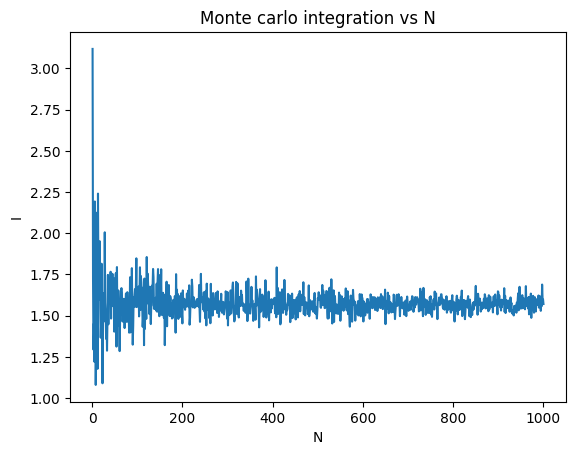

In [7]:
I=[]
n=np.linspace(1,1000,1000)
for i in range(1000):
    I.append(montyn(f,0,np.pi,i+1))
plt.plot(n,I)
plt.xlabel("N"); plt.ylabel("I")
plt.title("Monte carlo integration vs N")

In [8]:
N=1000
rng = np.random.default_rng()
p=rng.uniform(-1,1,size=(N,2)) #prints two numbers each time both between a,b and does it N times
x=p[:,0] #first column   
y=p[:,1] #second column  

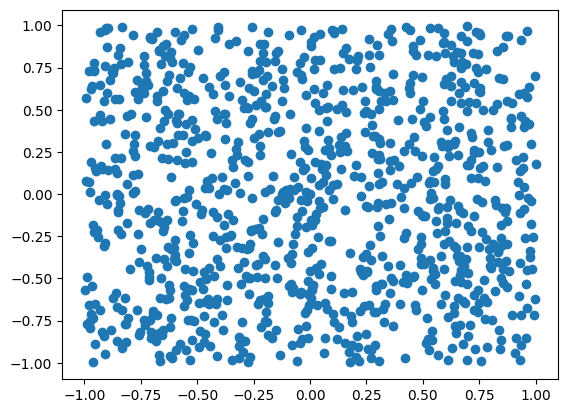

In [9]:
plt.scatter(x,y)

In [10]:
def region(x, y):
    return x**2 + y**2 <= 1 #very simple because python will just check if the equation is true or false


In [11]:
region(x,y)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False, False,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True, False, False,  True,  True, False, False,
        True,  True, False,  True, False,  True,  True, False, False,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False, False,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True, False,  True, False,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True, False,
       False,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True,  True,  True,  True,  True,
       False, False,

In [12]:
inside = region(x, y)      # fx [True, False, True, ...]



In [13]:
x_in = x[inside]
y_in = y[inside]

In [14]:
len(x_in)

785

In [15]:
from scipy.stats import qmc
M=10 # I get 2^M points
sampler=qmc.Sobol(d=2) #initialize the generator in 2d so i get x and y each time
p=sampler.random_base2(M) # creates 2^M sobolt points between 0 and 1
p=2*p-1

x,y=p[:,0],p[:,1]

In [16]:
def monty2d(f,region,a,b,M):
    I=0
    V=abs(b-a)**2 #the volume of a 2d function is the area
    sampler=qmc.Sobol(d=2) #initialize the generator in 2d so i get x and y each time
    N=2**M
    p=sampler.random_base2(M)
    x,y =(b-a)*p[:,0]+a,(b-a)*p[:,1]+a
    inside=region(x,y)
    I=np.sum(f( x[inside],y[inside]))
    return(I*V/N)

In [17]:
f = lambda x, y: np.ones_like(x)    # f = 1
print(monty2d(f, region, -1, 1, 10))   # skal give ca. 3.14

3.1328125
